# طراحی معکوس (Inverse Design) مدولاتور ماخ-زندر (MZI) با Meep

همه اعداد از نوت‌بوک قبلی شما آمده است: فناوری (Si 220 nm روی SiO2)، عرض موجبر `w = 0.45 µm`،
فاصله پورت‌ها `hs = ±1.5 µm`، شعاع خم `R = 3 µm`، باند 1.5–1.6 µm، مدل 2D با ضریب شکست مؤثر.

**روش (سه مرحله):**
1. **Topology optimization** (adjoint در `meep.adjoint`) یک کوپلر ۲×۲ فشرده 50:50 که جای کوپلرهای جهت‌دار بلند نوت‌بوک قبلی (~۱۰–۲۰ µm) می‌نشیند.
2. **طراحی معکوس اختلاف مسیر ΔL**: با داشتن t,k واقعی کوپلر و n_eff(λ)، ΔL طوری حل می‌شود که طیف MZI به هدف (FSR و قلهٔ دلخواه) برسد.
3. **راستی‌آزمایی FDTD** کل MZI + خروجی `.gds` و `.npz`.

> قبل از اجرای کامل: `QUICK_TEST = True` بگذارید و مطمئن شوید همه چیز بدون خطا اجرا می‌شود.

In [1]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:17
🔁 Restarting kernel...


In [1]:
!mamba install -y -q -c conda-forge pymeep autograd scipy matplotlib
!pip install -q gdstk

warning  libmamba [numpy-2.5.5-py313hb5f73ae_1] The following files were already present in the environment:
    - bin/f2py
    - bin/numpy-config
warning  libmamba [fonttools-4.68.0-py313h2af15c8_1] The following files were already present in the environment:
    - bin/fonttools
    - bin/pyftmerge
    - bin/pyftsubset
    - bin/ttx
    - share/man/man1/ttx.1


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np
ROOT = '/content/drive/MyDrive/MZI_inverse_design '
for d in ['data', 'figs', 'tables']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)

def cached(name, fn, *args, force=False, **kwargs):
    """اگر فایل نتیجه وجود دارد بارگذاری کن، وگرنه اجرا و ذخیره کن."""
    path = f'{ROOT}/data/{name}.npz'
    if os.path.exists(path) and not force:
        print(f'[cache] loaded {name}')
        return dict(np.load(path, allow_pickle=True))
    out = fn(*args, **kwargs)
    np.savez(path, **out)
    print(f'[saved] {name}')
    return out

Mounted at /content/drive


## ۰) پارامترها (از نوت‌بوک شما)

In [11]:
import time
import numpy as np
import matplotlib.pyplot as plt
import meep as mp
import meep.adjoint as mpa
from autograd import numpy as npa
from autograd import tensor_jacobian_product
from scipy.optimize import minimize_scalar

try:
    mp.verbosity(0)
except Exception:
    pass

# ======================= switches =======================
QUICK_TEST = False      # True: tiny/fast run only to check that the pipeline works
GRAD_CHECK = False      # True: compare adjoint gradient with finite differences before optimizing

RES_OPT = 12 if QUICK_TEST else 20      # px/um during optimization
RES_VER = 20 if QUICK_TEST else 32      # px/um for verification runs
NF_OPT = 3 if QUICK_TEST else 5         # wavelengths used in the optimization
NF_SPEC = 11 if QUICK_TEST else 31      # wavelengths used in verification spectra
PARITY = mp.EVEN_Z                      # TE-like mode (same as the original notebook)

# ======================= technology (original notebook) =======================
t_si, n_clad, n_si = 0.22, 1.444, 3.476


def slab_neff(t, n1=n_si, n2=n_clad, lam0=1.55):
    k0 = 2 * np.pi / lam0
    a = k0 * t / 2
    V = a * np.sqrt(n1 ** 2 - n2 ** 2)
    lo, hi = 1e-9, min(V, np.pi / 2 - 1e-9)
    f = lambda u: u * np.tan(u) - np.sqrt(max(V ** 2 - u ** 2, 0.0))
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if f(mid) > 0:
            hi = mid
        else:
            lo = mid
    u = 0.5 * (lo + hi)
    return float(np.sqrt(n1 ** 2 - (u / a) ** 2))


n_core = slab_neff(t_si)
print(f"2D effective core index: {n_core:.4f}")
Si2D = mp.Medium(index=n_core)
SiO2 = mp.Medium(index=n_clad)

# ======================= geometry (original notebook) =======================
w = 0.45          # strip width
hs = 1.5          # port half-separation (ports at y = +-hs)
R_BEND = 3.0      # arm bend radius
Lb, Lg, V0 = 0.5, 1.5, 0.0

# ======================= spectral band (original notebook) =======================
dpml = 1.0
fmin, fmax = 1 / 1.6, 1 / 1.5
fmid, fspan = 0.5 * (fmin + fmax), fmax - fmin
fcen_src, fwidth_src = 1 / 1.55, 0.12
src_size = 1.6
NG_EST = 3.3      # only used to choose the run time

# ======================= inverse-design region =======================
DR_X, DR_Y = 6.0, 4.0        # design region size (um)  -> compact coupler footprint
PORT_STUB = 0.4              # port stubs forced solid at the region edges (um)
FILTER_R = 0.15              # conic filter radius (um) ~ minimum feature size
ETA = 0.5
W_REFL = 0.5                 # weight of the reflection penalty

# Meep's conic_filter works on a grid of (L*res + 1) points per axis (odd, endpoints included)
Nx = int(DR_X * RES_OPT) + 1
Ny = int(DR_Y * RES_OPT) + 1
assert Ny % 2 == 1, "DR_Y*RES_OPT must be even so that the grid has a centre row"
Nyh = (Ny + 1) // 2          # free rows: from y = -DR_Y/2 up to the centre row y = 0

# ======================= single-coupler simulation cell =======================
wg_len = 2.5
sx = DR_X + 2 * (wg_len + dpml)
sy = DR_Y + 2 * dpml + 1.6
XS_C, XMI_C, XMO_C = -DR_X / 2 - 1.8, -DR_X / 2 - 1.2, DR_X / 2 + 1.5
T_C = NG_EST * sx + 40

2D effective core index: 2.8478


## ۱) طراحی معکوس کوپلر ۲×۲ (۳ دسی‌بل)

- ناحیهٔ طراحی `6×4 µm`، متقارن نسبت به محور `y` (در نتیجه ورودی `P0` و `P1` رفتار یکسان دارند و اختلاف فاز ۹۰° بین عبور و تزویج به‌طور فیزیکی برقرار می‌شود).
- هدف: `|S(P2,P0)|² = |S(P3,P0)|² = 0.5` روی کل باند 1.5–1.6 µm و حداقل بازتاب.
- فیلتر مخروطی + پروجکشن tanh با β پلکانی برای باینری‌شدن.

In [12]:
# ---------------- helpers: design mapping ----------------
xs_pix = np.linspace(-DR_X / 2, DR_X / 2, Nx)
ys_pix = np.linspace(-DR_Y / 2, DR_Y / 2, Ny)
MASK = (((xs_pix < -DR_X / 2 + PORT_STUB) | (xs_pix > DR_X / 2 - PORT_STUB))[:, None]
        & (np.abs(np.abs(ys_pix) - hs) <= w / 2)[None, :]).astype(float)   # solid port stubs


def mapping(x, eta, beta):
    half = npa.reshape(x, (Nx, Nyh))
    full = npa.concatenate([half, half[:, -2::-1]], axis=1)      # mirror symmetry about the centre row (y = 0)
    full = full * (1 - MASK) + MASK                              # keep ports connected
    filt = mpa.conic_filter(npa.ravel(full), FILTER_R, DR_X, DR_Y, RES_OPT)
    proj = mpa.tanh_projection(filt, beta, eta)
    return npa.ravel(proj)


def stub_blocks():
    xl, xr = -DR_X / 2 + 0.3, DR_X / 2 - 0.3
    out = []
    for yc in (-hs, +hs):
        L0, R0 = -sx, xl            # left stub spans [-sx, xl]
        out.append(mp.Block(size=mp.Vector3(R0 - L0, w, mp.inf), center=mp.Vector3(0.5 * (L0 + R0), yc, 0), material=Si2D))
        L1, R1 = xr, sx             # right stub spans [xr, sx]
        out.append(mp.Block(size=mp.Vector3(R1 - L1, w, mp.inf), center=mp.Vector3(0.5 * (L1 + R1), yc, 0), material=Si2D))
    return out


def make_sim(geometry, res):
    src = mp.EigenModeSource(mp.GaussianSource(fcen_src, fwidth=fwidth_src),
                             center=mp.Vector3(XS_C, -hs, 0), size=mp.Vector3(0, src_size, 0),
                             eig_band=1, eig_parity=PARITY, eig_match_freq=True)
    return mp.Simulation(cell_size=mp.Vector3(sx, sy, 0), boundary_layers=[mp.PML(dpml)],
                         geometry=geometry, sources=[src], default_material=SiO2,
                         resolution=res, dimensions=2)


def vol(x, y):
    return mp.Volume(center=mp.Vector3(x, y, 0), size=mp.Vector3(0, src_size, 0))


def ref_alpha(res, nf):
    # straight waveguide at P0 -> incident-mode amplitude (normalisation)
    geo = [mp.Block(size=mp.Vector3(mp.inf, w, mp.inf), center=mp.Vector3(0, -hs, 0), material=Si2D)]
    sim = make_sim(geo, res)
    mon = sim.add_mode_monitor(fmid, fspan, nf, mp.ModeRegion(center=mp.Vector3(XMO_C, -hs, 0), size=mp.Vector3(0, src_size, 0)))
    sim.run(until_after_sources=T_C)
    a = np.array(sim.get_eigenmode_coefficients(mon, [1], eig_parity=PARITY).alpha[0])[:, 0]
    return a, np.array(mp.get_flux_freqs(mon))


print("Reference run for optimization normalisation ...")
a_ref_opt, freqs_opt = ref_alpha(RES_OPT, NF_OPT)
ref_pow = np.abs(a_ref_opt) ** 2
print("optimization wavelengths (um):", np.round(1 / freqs_opt, 4))

Reference run for optimization normalisation ...


FloatProgress(value=0.0, description='0% done ', max=166.23333587646485)

optimization wavelengths (um): [1.6    1.5738 1.5484 1.5238 1.5   ]


In [13]:
# ---------------- optimisation problem ----------------
design_variables = mp.MaterialGrid(mp.Vector3(Nx, Ny), SiO2, Si2D, grid_type="U_MEAN")
design_region = mpa.DesignRegion(design_variables,
                                 volume=mp.Volume(center=mp.Vector3(), size=mp.Vector3(DR_X, DR_Y, 0)))
geo_opt = stub_blocks() + [mp.Block(center=mp.Vector3(), size=mp.Vector3(DR_X, DR_Y, 0), material=design_variables)]
sim_opt = make_sim(geo_opt, RES_OPT)

ob_thru = mpa.EigenmodeCoefficient(sim_opt, vol(XMO_C, -hs), 1, eig_parity=PARITY)                  # P0 -> P2
ob_cross = mpa.EigenmodeCoefficient(sim_opt, vol(XMO_C, +hs), 1, eig_parity=PARITY)                 # P0 -> P3
ob_refl = mpa.EigenmodeCoefficient(sim_opt, vol(XMI_C, -hs), 1, forward=False, eig_parity=PARITY)   # reflection


def J(a_t, a_k, a_r):
    Pt = npa.abs(a_t) ** 2 / ref_pow
    Pk = npa.abs(a_k) ** 2 / ref_pow
    Pr = npa.abs(a_r) ** 2 / ref_pow
    return -npa.mean((Pt - 0.5) ** 2 + (Pk - 0.5) ** 2 + W_REFL * Pr)      # maximise (0 is ideal)


opt = mpa.OptimizationProblem(simulation=sim_opt, objective_functions=[J],
                              objective_arguments=[ob_thru, ob_cross, ob_refl],
                              design_regions=[design_region], frequencies=freqs_opt,
                              decay_by=1e-5, maximum_run_time=250)


def reduce_grad(dJ, n):
    dJ = np.squeeze(np.asarray(dJ, dtype=float))
    if dJ.ndim == 2:
        dJ = dJ.sum(axis=1) if dJ.shape[0] == n else dJ.sum(axis=0)
    assert dJ.size == n, f"unexpected gradient shape {dJ.shape}"
    return dJ


def fom_and_grad(x, beta):
    f0, dJ = opt([mapping(x, ETA, beta)])
    g = tensor_jacobian_product(mapping, 0)(x, ETA, beta, reduce_grad(dJ, Nx * Ny))
    return float(np.real(np.squeeze(f0))), np.asarray(g)


rng = np.random.default_rng(0)
x0 = np.clip(0.5 + 0.05 * rng.standard_normal(Nx * Nyh), 0, 1)

In [14]:
# ---------------- optional: adjoint vs finite-difference gradient ----------------
if GRAD_CHECK:
    beta_t = 4.0
    f_c, g_c = fom_and_grad(x0, beta_t)
    for i in rng.choice(Nx * Nyh, 3, replace=False):
        d = 0.02
        xp, xm = x0.copy(), x0.copy(); xp[i] += d; xm[i] -= d
        fp, _ = fom_and_grad(xp, beta_t); fm, _ = fom_and_grad(xm, beta_t)
        print(f"idx {i}: adjoint = {g_c[i]: .3e}   finite-diff = {(fp - fm) / (2 * d): .3e}")

/usr/local/lib/python3.13/site-packages/meep/geom.py:598: UserWarning: The weights parameter of MaterialGrid must be in the range [0,1].
  warnings.warn(


Starting forward run...


Starting adjoint run...
Calculating gradient...


beta=  2  it= 1/15  J=-0.39698  (7 s)
Starting forward run...


Starting adjoint run...
Calculating gradient...


beta=  2  it= 2/15  J=-0.33259  (10 s)
Starting forward run...


... (142 outputs left out)

Starting adjoint run...
Calculating gradient...


beta= 64  it=13/15  J=-0.00200  (9 s)
Starting forward run...


Starting adjoint run...
Calculating gradient...
beta= 64  it=14/15  J=-0.00177  (7 s)
Starting forward run...


Starting adjoint run...
Calculating gradient...
beta= 64  it=15/15  J=-0.00146  (9 s)
Optimisation finished in 12.3 min


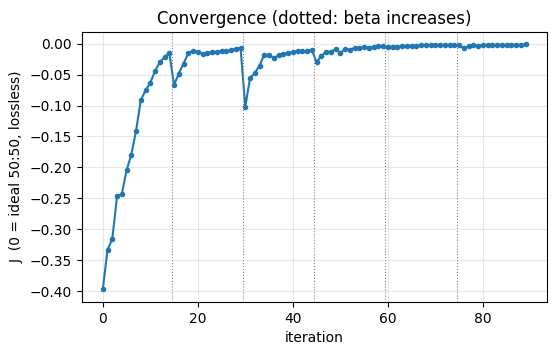

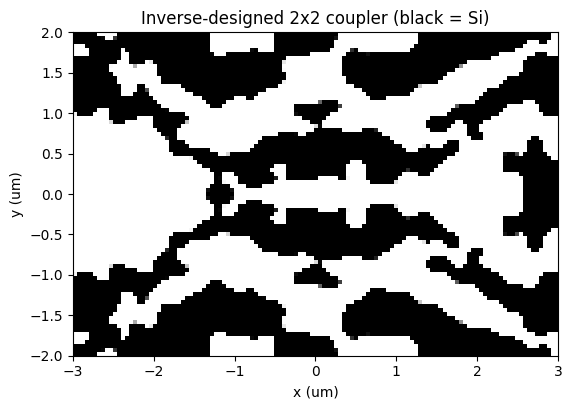

In [15]:
# ---------------- run the optimisation (Adam + beta continuation) ----------------
BETAS = [2, 4, 8, 16, 32, 64]
N_IT = [2] * len(BETAS) if QUICK_TEST else [15] * len(BETAS)
LR = 0.06

x = x0.copy(); m = np.zeros_like(x); v = np.zeros_like(x); step = 0
J_hist, beta_hist = [], []
t_start = time.time()
for beta, nit in zip(BETAS, N_IT):
    for it in range(nit):
        t0 = time.time()
        f0, g = fom_and_grad(x, beta)
        step += 1
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g * g
        x = np.clip(x + LR * (m / (1 - 0.9 ** step)) / (np.sqrt(v / (1 - 0.999 ** step)) + 1e-8), 0, 1)
        J_hist.append(f0); beta_hist.append(beta)
        print(f"beta={beta:>3}  it={it + 1:>2}/{nit}  J={f0: .5f}  ({time.time() - t0:.0f} s)")
print(f"Optimisation finished in {(time.time() - t_start) / 60:.1f} min")

plt.figure(figsize=(6, 3.5))
plt.plot(J_hist, "o-", ms=3)
for i in np.where(np.diff(beta_hist) != 0)[0]:
    plt.axvline(i + 0.5, color="gray", ls=":", lw=0.8)
plt.xlabel("iteration"); plt.ylabel("J  (0 = ideal 50:50, lossless)"); plt.grid(alpha=0.3)
plt.title("Convergence (dotted: beta increases)"); plt.show()

np.save("coupler_design_x.npy", x)
rho_final = np.asarray(mapping(x, ETA, 256.0)).reshape(Nx, Ny)        # binary design
np.save("coupler_design_rho.npy", rho_final)

plt.figure(figsize=(7, 4.2))
plt.imshow(rho_final.T, origin="lower", cmap="gray_r", extent=[-DR_X / 2, DR_X / 2, -DR_Y / 2, DR_Y / 2])
plt.xlabel("x (um)"); plt.ylabel("y (um)"); plt.title("Inverse-designed 2x2 coupler (black = Si)")
plt.show()

## ۲) راستی‌آزمایی کوپلر با رزولوشن بالاتر (FDTD)

Coupler verification (reference) ...


FloatProgress(value=0.0, description='0% done ', max=166.23333587646485)

Coupler verification (device) ...


FloatProgress(value=0.0, description='0% done ', max=166.23333587646485)

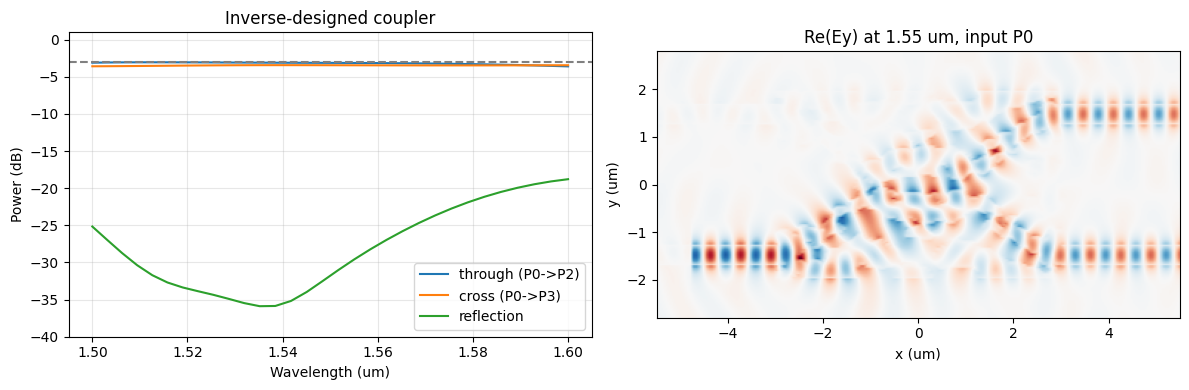

At 1.55 um : through 0.489   cross 0.454   reflection 0.0006
Band mean  : excess loss 0.302 dB | imbalance 0.308 dB
Phase(k/t) : 89.7 deg (ideal coupler: +-90)


In [16]:
def run_coupler(rho2d, res, nf):
    geo = stub_blocks() + [mp.Block(center=mp.Vector3(), size=mp.Vector3(DR_X, DR_Y, 0),
                                    material=mp.MaterialGrid(mp.Vector3(Nx, Ny), SiO2, Si2D, weights=rho2d,
                                                             do_averaging=False, grid_type="U_MEAN"))]
    sim = make_sim(geo, res)
    names = {"in": (XMI_C, -hs), "thru": (XMO_C, -hs), "cross": (XMO_C, +hs)}
    mons = {k: sim.add_mode_monitor(fmid, fspan, nf, mp.ModeRegion(center=mp.Vector3(cx, cy, 0),
                                                                   size=mp.Vector3(0, src_size, 0)))
            for k, (cx, cy) in names.items()}
    dft = sim.add_dft_fields([mp.Ey], fcen_src, 0, 1,
                             where=mp.Volume(center=mp.Vector3(), size=mp.Vector3(sx - 2 * dpml, sy - 2 * dpml, 0)))
    sim.run(until_after_sources=T_C)
    al = {k: np.array(sim.get_eigenmode_coefficients(mn, [1], eig_parity=PARITY).alpha[0]) for k, mn in mons.items()}
    fld = np.real(sim.get_dft_array(dft, mp.Ey, 0))
    return al, np.array(mp.get_flux_freqs(mons["thru"])), fld


print("Coupler verification (reference) ...")
a_ref_v, freqs = ref_alpha(RES_VER, NF_SPEC)
print("Coupler verification (device) ...")
al, _, fld_c = run_coupler(rho_final, RES_VER, NF_SPEC)
t_cpl = al["thru"][:, 0] / a_ref_v          # complex S(P2,P0)
k_cpl = al["cross"][:, 0] / a_ref_v         # complex S(P3,P0)
r_cpl = al["in"][:, 1] / a_ref_v            # reflection at P0
lam = 1.0 / freqs
idx_c = int(np.argmin(np.abs(freqs - 1 / 1.55)))
dB = lambda z: 10 * np.log10(np.maximum(np.abs(z) ** 2, 1e-12))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(lam, dB(t_cpl), label="through (P0->P2)")
ax[0].plot(lam, dB(k_cpl), label="cross (P0->P3)")
ax[0].plot(lam, dB(r_cpl), label="reflection")
ax[0].axhline(-3.01, color="gray", ls="--"); ax[0].set_ylim(-40, 1)
ax[0].set_xlabel("Wavelength (um)"); ax[0].set_ylabel("Power (dB)"); ax[0].grid(alpha=0.3); ax[0].legend()
ax[0].set_title("Inverse-designed coupler")
ext = [-(sx - 2 * dpml) / 2, (sx - 2 * dpml) / 2, -(sy - 2 * dpml) / 2, (sy - 2 * dpml) / 2]
vmax = np.max(np.abs(fld_c))
ax[1].imshow(fld_c.T, origin="lower", extent=ext, cmap="RdBu", vmin=-vmax, vmax=vmax)
ax[1].set_title("Re(Ey) at 1.55 um, input P0"); ax[1].set_xlabel("x (um)"); ax[1].set_ylabel("y (um)")
plt.tight_layout(); plt.show()

Tt, Kk = np.abs(t_cpl) ** 2, np.abs(k_cpl) ** 2
print(f"At 1.55 um : through {Tt[idx_c]:.3f}   cross {Kk[idx_c]:.3f}   reflection {np.abs(r_cpl[idx_c])**2:.4f}")
print(f"Band mean  : excess loss {np.mean(-10*np.log10(Tt + Kk)):.3f} dB | imbalance {np.mean(np.abs(10*np.log10(Tt/Kk))):.3f} dB")
print(f"Phase(k/t) : {np.degrees(np.angle(k_cpl / t_cpl)).mean():.1f} deg (ideal coupler: +-90)")

## ۳) طراحی معکوس اختلاف مسیر ΔL

هدف را خودتان تعیین کنید: طول موج قلهٔ خروجی `P2` و FSR دلخواه. مدل مدار با **t و k مختلط واقعی** کوپلر طراحی‌شده
و `n_eff(λ)` از حل‌گر مود Meep ساخته می‌شود و ΔL با کمینه‌کردن خطا نسبت به طیف هدف پیدا می‌شود.

n_eff(1.55) = 2.4069,  n_g = 3.182
==> Inverse-designed path difference  DL = 15.782 um   (cost 7.33e-03)
    expected FSR = 47.8 nm  (target 50 nm)


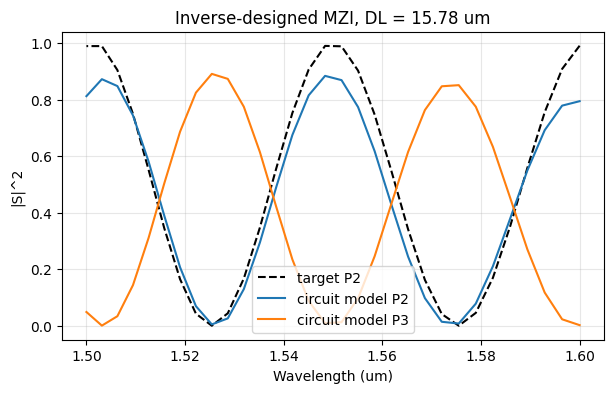

In [17]:
# ======================= TARGET SPECIFICATION (edit me) =======================
LAMBDA0 = 1.55       # um : wavelength where P2 should peak
FSR_TARGET = 0.05    # um : desired free spectral range

def neff_curve(freq_list, width, n_core_, res):
    sim = mp.Simulation(cell_size=mp.Vector3(1, 5, 0),
                        geometry=[mp.Block(size=mp.Vector3(mp.inf, width, mp.inf), center=mp.Vector3(),
                                           material=mp.Medium(index=n_core_))],
                        default_material=SiO2, resolution=res, dimensions=2)
    sim.init_sim()
    vol_ = mp.Volume(center=mp.Vector3(), size=mp.Vector3(0, 4, 0))
    return np.array([sim.get_eigenmode(f, mp.X, vol_, 1, mp.Vector3(2.3 * f, 0, 0), parity=PARITY).k.x / f
                     for f in freq_list])

f_sub = np.linspace(freqs.min(), freqs.max(), 11)
neff_sub = neff_curve(f_sub, w, n_core, RES_VER)
neff_nom = np.interp(freqs, f_sub, neff_sub)
lam_sub = 1 / f_sub
ng = neff_sub - lam_sub * np.gradient(neff_sub, lam_sub)
ng_c = float(np.interp(1 / LAMBDA0, f_sub, ng))
print(f"n_eff(1.55) = {neff_nom[idx_c]:.4f},  n_g = {ng_c:.3f}")


def mzi_S(neff, lam_, t, k, DLx):
    # circuit model with the *measured complex* coupler amplitudes (Meep convention exp(-i w t) -> +i*phi)
    e_l, e_u = 1.0, np.exp(1j * 2 * np.pi * neff * DLx / lam_)
    return {("P0", "P2"): t * t * e_l + k * k * e_u, ("P0", "P3"): t * k * (e_l + e_u),
            ("P1", "P2"): t * k * (e_l + e_u),       ("P1", "P3"): k * k * e_l + t * t * e_u}


f0_t = 1 / LAMBDA0
FSR_f = FSR_TARGET / LAMBDA0 ** 2
target_P2 = np.cos(np.pi * (freqs - f0_t) / FSR_f) ** 2          # peak at LAMBDA0, period = FSR
cost = lambda d: np.mean((np.abs(mzi_S(neff_nom, lam, t_cpl, k_cpl, d)[("P0", "P2")]) ** 2 - target_P2) ** 2)

scan = np.arange(1.0, 40.0, 0.01)
DL_guess = scan[int(np.argmin([cost(d) for d in scan]))]
res_ = minimize_scalar(cost, bounds=(DL_guess - 0.05, DL_guess + 0.05), method="bounded")
DL_OPT = float(res_.x)
print(f"==> Inverse-designed path difference  DL = {DL_OPT:.3f} um   (cost {res_.fun:.2e})")
print(f"    expected FSR = {LAMBDA0**2 / (ng_c * DL_OPT) * 1e3:.1f} nm  (target {FSR_TARGET*1e3:.0f} nm)")

S_an = mzi_S(neff_nom, lam, t_cpl, k_cpl, DL_OPT)
plt.figure(figsize=(7, 4))
plt.plot(lam, target_P2, "k--", label="target P2")
plt.plot(lam, np.abs(S_an[("P0", "P2")]) ** 2, label="circuit model P2")
plt.plot(lam, np.abs(S_an[("P0", "P3")]) ** 2, label="circuit model P3")
plt.xlabel("Wavelength (um)"); plt.ylabel("|S|^2"); plt.grid(alpha=0.3); plt.legend()
plt.title(f"Inverse-designed MZI, DL = {DL_OPT:.2f} um"); plt.show()

## ۴) شبیه‌سازی FDTD کل MZI (دو کوپلر طراحی‌شده + بازوها)

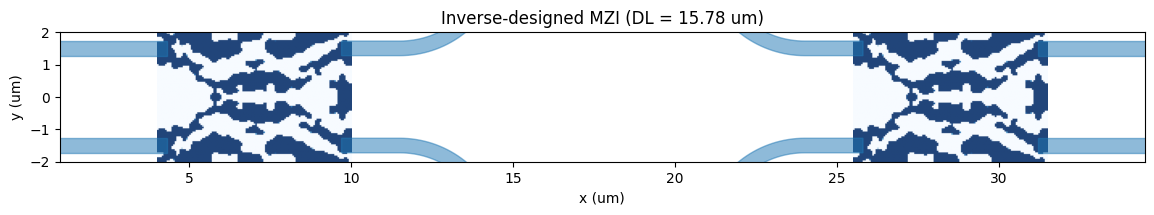

In [18]:
class CL:
    def __init__(self, x, y):
        self.x, self.y, self.th = float(x), float(y), 0.0
        self.p = [np.array([[self.x, self.y]])]

    def straight(self, L):
        if L > 1e-12:
            self.x += L * np.cos(self.th); self.y += L * np.sin(self.th)
            self.p.append(np.array([[self.x, self.y]]))
        return self

    def arc(self, R, ang, n=40):          # ang > 0: left turn
        sg = np.sign(ang)
        cx = self.x - sg * R * np.sin(self.th); cy = self.y + sg * R * np.cos(self.th)
        a0 = np.arctan2(self.y - cy, self.x - cx)
        a = a0 + np.linspace(0, ang, n + 1)[1:]
        pts = np.column_stack((cx + R * np.cos(a), cy + R * np.sin(a)))
        self.p.append(pts)
        self.x, self.y = float(pts[-1, 0]), float(pts[-1, 1]); self.th += ang
        return self

    def pts(self):
        return np.vstack(self.p)


def to_polygon(c, width):
    x, y = c[:, 0], c[:, 1]
    dx, dy = np.gradient(x), np.gradient(y)
    nrm = np.hypot(dx, dy); nx, ny = -dy / nrm, dx / nrm
    up = np.column_stack((x + nx * width / 2, y + ny * width / 2))
    lo = np.column_stack((x - nx * width / 2, y - ny * width / 2))
    return np.vstack((up, lo[::-1]))


def prism(poly):
    return mp.Prism([mp.Vector3(float(a), float(b), -500.0) for a, b in poly], height=1000.0, material=Si2D)


X1 = 4.0                                   # left edge of coupler 1 (um)


def mzi_dims(DLx):
    Vu = V0 + DLx / 2.0
    X1r = X1 + DR_X
    X2 = X1r + 2 * Lg + 4 * R_BEND + Lb
    X2r = X2 + DR_X
    xmo = X2r + 1.2
    xmax = xmo + 0.8 + dpml
    ytop = hs + 2 * R_BEND + Vu + w / 2 + 0.8 + dpml
    ybot = -(hs + 2 * R_BEND + V0 + w / 2 + 0.8 + dpml)
    return dict(X1r=X1r, X2=X2, X2r=X2r, xmo=xmo, xmax=xmax, ytop=ytop, ybot=ybot)


def arm_polys(DLx, x_start=-3.0, x_stop=None):
    d = mzi_dims(DLx)
    if x_stop is None:
        x_stop = d["xmax"] + 3.0
    ov = 0.3                                # overlap of arms into the coupler stubs
    polys = []
    for sign in (-1, +1):                   # -1: lower (reference) arm, +1: upper (delay) arm
        V = V0 + (DLx / 2.0 if sign > 0 else 0.0)
        polys.append(to_polygon(CL(x_start, sign * hs).straight(X1 + ov - x_start).pts(), w))          # input stub
        c = CL(d["X1r"] - ov, sign * hs).straight(ov + Lg)
        c.arc(R_BEND, sign * np.pi / 2).straight(V).arc(R_BEND, -sign * np.pi / 2)
        c.straight(Lb)
        c.arc(R_BEND, -sign * np.pi / 2).straight(V).arc(R_BEND, sign * np.pi / 2)
        c.straight(Lg + ov)
        assert abs(c.x - (d["X2"] + ov)) < 1e-6, (c.x, d["X2"])
        polys.append(to_polygon(c.pts(), w))                                                            # arm
        polys.append(to_polygon(CL(d["X2r"] - ov, sign * hs).straight(x_stop - d["X2r"] + ov).pts(), w))  # output stub
    return polys


def mzi_geometry(DLx, rho2d):
    geo = [prism(p) for p in arm_polys(DLx)]
    for xl in (X1, mzi_dims(DLx)["X2"]):
        geo.append(mp.Block(center=mp.Vector3(xl + DR_X / 2, 0, 0), size=mp.Vector3(DR_X, DR_Y, 0),
                            material=mp.MaterialGrid(mp.Vector3(Nx, Ny), SiO2, Si2D, weights=rho2d,
                                                     do_averaging=False, grid_type="U_MEAN")))
    return geo


# ---- geometry preview
fig, ax = plt.subplots(figsize=(14, 6))
for p in arm_polys(DL_OPT):
    ax.fill(p[:, 0], p[:, 1], color="C0", alpha=0.5)
for xl in (X1, mzi_dims(DL_OPT)["X2"]):
    ax.imshow(rho_final.T, origin="lower", cmap="Blues", extent=[xl, xl + DR_X, -DR_Y / 2, DR_Y / 2], alpha=0.9)
ax.set_xlim(X1 - 3, mzi_dims(DL_OPT)["X2r"] + 3); ax.set_aspect("equal")
ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)"); ax.set_title(f"Inverse-designed MZI (DL = {DL_OPT:.2f} um)")
plt.show()

In [19]:
x_src, x_mon_in = 1.6, 2.2


def run_fdtd(geometry, bounds, src_y, mons, path_len, nf, res, want_field=False):
    x0_, x1_, y0_, y1_ = bounds
    t0 = time.time()
    src = mp.EigenModeSource(mp.GaussianSource(fcen_src, fwidth=fwidth_src),
                             center=mp.Vector3(x_src, src_y, 0), size=mp.Vector3(0, src_size, 0),
                             eig_band=1, eig_parity=PARITY, eig_match_freq=True)
    sim = mp.Simulation(cell_size=mp.Vector3(x1_ - x0_, y1_ - y0_, 0),
                        geometry_center=mp.Vector3(0.5 * (x0_ + x1_), 0.5 * (y0_ + y1_), 0),
                        boundary_layers=[mp.PML(dpml)], geometry=geometry, sources=[src],
                        default_material=SiO2, resolution=res, dimensions=2)
    mo = {k: sim.add_mode_monitor(fmid, fspan, nf, mp.ModeRegion(center=mp.Vector3(cx, cy, 0),
                                                                 size=mp.Vector3(0, src_size, 0)))
          for k, (cx, cy) in mons.items()}
    dft = None
    if want_field:
        dft = sim.add_dft_fields([mp.Ey], fcen_src, 0, 1,
                                 where=mp.Volume(center=mp.Vector3(0.5 * (x0_ + x1_), 0.5 * (y0_ + y1_), 0),
                                                 size=mp.Vector3(x1_ - x0_ - 2 * dpml, y1_ - y0_ - 2 * dpml, 0)))
    sim.run(until_after_sources=NG_EST * path_len + 40)
    al_ = {k: np.array(sim.get_eigenmode_coefficients(m_, [1], eig_parity=PARITY).alpha[0]) for k, m_ in mo.items()}
    fld = np.real(sim.get_dft_array(dft, mp.Ey, 0)) if want_field else None
    print(f"   done in {time.time() - t0:.0f} s")
    return al_, fld


print("MZI reference run ...")
c_ref = CL(-3.0, -hs).straight(14.0)
ref_out, _ = run_fdtd([prism(to_polygon(c_ref.pts(), w))], (0, 8, -4, 4), -hs, {"m0": (x_mon_in, -hs)},
                      path_len=8, nf=NF_SPEC, res=RES_VER)
a_ref_m = ref_out["m0"][:, 0]

dm = mzi_dims(DL_OPT)
bounds = (0.0, dm["xmax"], dm["ybot"], dm["ytop"])
mons4 = {"m0": (x_mon_in, -hs), "m1": (x_mon_in, hs), "m2": (dm["xmo"], -hs), "m3": (dm["xmo"], hs)}
print("MZI device run (excite P0) ...")
d0, fld_m = run_fdtd(mzi_geometry(DL_OPT, rho_final), bounds, -hs, mons4,
                     dm["xmax"] + DL_OPT + 4 * R_BEND, NF_SPEC, RES_VER, want_field=True)
S = {("P0", "P0"): d0["m0"][:, 1] / a_ref_m, ("P0", "P1"): d0["m1"][:, 1] / a_ref_m,
     ("P0", "P2"): d0["m2"][:, 0] / a_ref_m, ("P0", "P3"): d0["m3"][:, 0] / a_ref_m}

MZI reference run ...


FloatProgress(value=0.0, description='0% done ', max=149.73333587646485)

   done in 6 s
MZI device run (excite P0) ...
WARNING vol mismatch:, original_vol 833600, looped vol_sum 832558 


FloatProgress(value=0.0, description='0% done ', max=328.86370391141855)

   done in 893 s


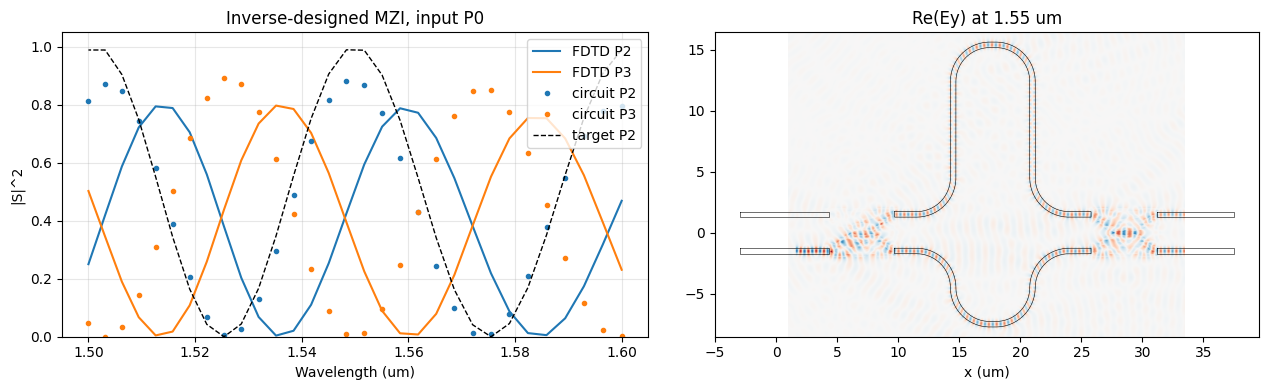

Mean excess loss (P0 input)   : 1.065 dB
Extinction (P2 min/max in band): 23.2 dB
Footprint of the two couplers  : 2 x 6 x 4 um^2


In [20]:
# ---------- FDTD vs target vs circuit model ----------
P2, P3 = np.abs(S[("P0", "P2")]) ** 2, np.abs(S[("P0", "P3")]) ** 2
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lam, P2, "C0-", label="FDTD P2"); ax[0].plot(lam, P3, "C1-", label="FDTD P3")
ax[0].plot(lam, np.abs(S_an[("P0", "P2")]) ** 2, "C0.", label="circuit P2")
ax[0].plot(lam, np.abs(S_an[("P0", "P3")]) ** 2, "C1.", label="circuit P3")
ax[0].plot(lam, target_P2, "k--", lw=1, label="target P2")
ax[0].set_xlabel("Wavelength (um)"); ax[0].set_ylabel("|S|^2"); ax[0].set_ylim(0, 1.05)
ax[0].grid(alpha=0.3); ax[0].legend(); ax[0].set_title("Inverse-designed MZI, input P0")

ext = [bounds[0] + dpml, bounds[1] - dpml, bounds[2] + dpml, bounds[3] - dpml]
vmax = np.max(np.abs(fld_m))
ax[1].imshow(fld_m.T, origin="lower", extent=ext, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="equal")
for p in arm_polys(DL_OPT):
    ax[1].plot(np.append(p[:, 0], p[0, 0]), np.append(p[:, 1], p[0, 1]), "k-", lw=0.4)
ax[1].set_title("Re(Ey) at 1.55 um"); ax[1].set_xlabel("x (um)")
plt.tight_layout(); plt.show()

tot = P2 + P3
print(f"Mean excess loss (P0 input)   : {np.mean(-10 * np.log10(tot)):.3f} dB")
print(f"Extinction (P2 min/max in band): {10 * np.log10(P2.max() / max(P2.min(), 1e-9)):.1f} dB")
print(f"Footprint of the two couplers  : 2 x {DR_X:.0f} x {DR_Y:.0f} um^2")

## ۵) ذخیرهٔ نتایج و خروجی GDS

In [21]:
np.savez("MZI_inverse_design_results.npz", wavelength_um=lam, DL_um=DL_OPT, rho=rho_final,
         **{f"S_{i}_{j}": s for (i, j), s in S.items()}, t_cpl=t_cpl, k_cpl=k_cpl)
print("Saved MZI_inverse_design_results.npz, coupler_design_rho.npy")

try:
    import gdstk
    from scipy.ndimage import zoom

    def design_to_polys(rho2d, x_left, up=4):
        big = zoom(rho2d, up, order=1) > 0.5                  # smooth the staircase
        px, py = DR_X / big.shape[0], DR_Y / big.shape[1]
        rects = []
        for iy in range(big.shape[1]):
            d_ = np.diff(np.concatenate([[0], big[:, iy].astype(np.int8), [0]]))
            for s_, e_ in zip(np.where(d_ == 1)[0], np.where(d_ == -1)[0]):
                rects.append(gdstk.rectangle((x_left + s_ * px, -DR_Y / 2 + iy * py),
                                             (x_left + e_ * px, -DR_Y / 2 + (iy + 1) * py)))
        return rects

    d_f = mzi_dims(DL_OPT)
    shapes = [gdstk.Polygon([tuple(p_) for p_ in poly], layer=2, datatype=0) for poly in arm_polys(DL_OPT, x_stop=d_f["X2r"] + 3.0)]
    for xl in (X1, d_f["X2"]):
        shapes += design_to_polys(rho_final, xl)
    merged = gdstk.boolean(shapes, [], "or", precision=1e-3, layer=2, datatype=0)
    lib = gdstk.Library(); cell_g = lib.new_cell("MZI_INVDES")
    for p_ in merged:
        cell_g.add(p_)
    lib.write_gds("MZI_inverse_design.gds")
    print("GDS written; polygons:", len(merged))
except Exception as e:
    print("GDS export skipped:", e)

# from google.colab import files; files.download("MZI_inverse_design.gds")

Saved MZI_inverse_design_results.npz, coupler_design_rho.npy
GDS written; polygons: 27
